# CDSCO NSQ Drug Quality Analysis (2019–2026)


## 1. Install the required libraries


In [1]:
%pip install pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


## 2. Import libraries

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.width", 140)

print("Current notebook folder:", Path.cwd())

Current notebook folder: C:\Windows\System32


## 3. Load your CSV directly



In [22]:
# Your CSV filename (extension may be .csv; case-insensitive search)
EXPECTED_BASENAME = "CDSCO_NSQ_2019_2026_WITH_QUALITY_CATEGORIES"

csv_files = [p for p in Path.cwd().iterdir() if p.is_file() and p.suffix.lower() == ".csv"]
matching_files = [
    p for p in csv_files
    if p.stem.lower() == EXPECTED_BASENAME.lower()
    or p.stem.lower().startswith(EXPECTED_BASENAME.lower())
]

if len(matching_files) == 1:
    CSV_PATH = matching_files[0]
elif len(matching_files) > 1:
    print("More than one matching CSV found:")
    for i, path in enumerate(matching_files):
        print(f"{i}: {path.name}")
    choice = int(input("Enter the number of the correct CSV: "))
    CSV_PATH = matching_files[choice]
else:
    print("CSV files in the current notebook folder:")
    for path in csv_files:
        print(" -", path.name)
    raise FileNotFoundError(
        f"Could not find a CSV starting with '{EXPECTED_BASENAME}' in {Path.cwd()}.\n"
        "Make sure the CSV and notebook are in the same folder, and the notebook's "
        "current working directory is that folder."
    )

df_raw = pd.read_csv(CSV_PATH, low_memory=False)
df = df_raw.copy()

print("Loaded file:", CSV_PATH.name)
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")
display(df.head())

Loaded file: CDSCO_NSQ_2019_2026_WITH_QUALITY_CATEGORIES.csv
Rows: 6,609
Columns: 23


,report_year,report_month,report_month_name,reporting_month_year,product_name,product_short_name,batch_no,manufacturing_date,expiry_date,manufactured_by,manufacturer_short_name,nsq_result,nsq_result_short_name,reporting_source,reported_by_lab_or_state,manufacturer_address,manufacturer_city,manufacturer_state,quality_category,category_chemical_content,category_physical,category_microbiological,category_other_identity
0,2019,1,Jan,01-01-2019,Amoxycillin & Potassium Clavulanete Tablets I.P. (Amofive CL 625),Amoxycillin & Potassium Clavulanete Tablets,SBPT-4686,01-05-2018,01-10-2019,"M/s. Saitech Medicare Pvt. Ltd., Trilokpur Road, Kala-Amb, H.P.-173030",M/s. Saitech Medicare Pvt. Ltd,Assay of Amoxycillin & Dissolution,Assay + Dissolution,State Lab,RDTL Guwahati,"Trilokpur Road, Kala-Amb, H.P.-173030",Kala-Amb,Himachal Pradesh,Chemical/Content,1,0,0,0
1,2019,1,Jan,01-01-2019,Amoxycillin And Potassium Clavulanate Tablets I.P.,Amoxycillin & Potassium Clavulanate Tablets,SB58049,01-03-2018,01-02-2020,"M/s. Scott-Edil Pharmacia Ltd., 56, EPIP, Phase-I, Jharmajri-173205",M/s. Scott-Edil Pharmacia Ltd,"Assay of Amoxycillin, Assay of Clavulanic Acid & Dissolution",Assay + Dissolution,State Lab,RDTL Guwahati,"56, EPIP, Phase-I, Jharmajri-173205",Baddi,Himachal Pradesh,Chemical/Content,1,0,0,0
2,2019,1,Jan,01-01-2019,C-Furo 750 mg (Cefuroxime Injection IP),C-Furo 750 mg,B298005B,01-08-2018,01-07-2020,"M/s. ANG Life Sciences India Ltd., Village-Kishanpura, Nalagarh Road, Tehsil Baddi, Distt. Solan...",M/s. ANG Life Sciences India Ltd,Clarity of Solution & Particulate Matter,Particulate Matter + Clarity,CDSCO Lab,CDTL Mumbai,"Village-Kishanpura, Nalagarh Road, Tehsil Baddi, Distt. Solan, H.P.-174101",Solan,Himachal Pradesh,Physical,0,1,0,0
3,2019,1,Jan,01-01-2019,"COR-3 (L- Methylfolate, Methylcobalamin & Pyridoxal-5- phosphate Tablets)",COR-3,CG18034,01-04-2018,01-09-2019,"M/s. Corona Remedies Pvt. Ltd., Village Jatolli, P.O. Oachghat, Tahsil-Solan, Dist. Solan (HP)-1...",M/s. Corona Remedies Pvt. Ltd,Assay of L- Methylfolate & Pyridoxal-5- Phosphate,Assay,CDSCO Lab,CDTL Mumbai,"Village Jatolli, P.O. Oachghat, Tahsil-Solan, Dist. Solan (HP)-173223",Solan,Himachal Pradesh,Chemical/Content,1,0,0,0
4,2019,1,Jan,01-01-2019,Calcium and Vitamin D3 Tablets (ORTHOCAL-500 TABLETS),Calcium & Vitamin D3 Tablets,TP-3286,01-03-2018,01-02-2020,"B. No.: TP-3286, Mfg dt: 03/2018, Exp dt: 02/2020, Mfd by: M/s. Ticoma Pharmacia, E-17, Focal Po...",M/s. Ticoma Pharmacia,Assay of Vitamin D3,Assay,CDSCO Lab,"CDSCO, Sub Zone, Baddi.","E-17, Focal Point, Derabassi, Distt.Mohali (Punjab).",Mohali,Punjab,Chemical/Content,1,0,0,0


## 4. Check columns, data types, and basic profile

In [23]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

display(df.describe(include="all").T)

Column names:
['report_year', 'report_month', 'report_month_name', 'reporting_month_year', 'product_name', 'product_short_name', 'batch_no', 'manufacturing_date', 'expiry_date', 'manufactured_by', 'manufacturer_short_name', 'nsq_result', 'nsq_result_short_name', 'reporting_source', 'reported_by_lab_or_state', 'manufacturer_address', 'manufacturer_city', 'manufacturer_state', 'quality_category', 'category_chemical_content', 'category_physical', 'category_microbiological', 'category_other_identity']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6609 entries, 0 to 6608
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   report_year                6609 non-null   int64 
 1   report_month               6609 non-null   int64 
 2   report_month_name          6609 non-null   object
 3   reporting_month_year       6609 non-null   object
 4   product_name          

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
report_year,6609.0,NaN,NaN,NaN,2023.833863,2.100803,2019.0,2023.0,2025.0,2025.0,2026.0
report_month,6609.0,NaN,NaN,NaN,6.341655,3.455497,1.0,3.0,6.0,9.0,12.0
report_month_name,6609,12,Jul,654,NaN,NaN,NaN,NaN,NaN,NaN,NaN
reporting_month_year,6609,92,01-07-2026,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,6609,5189,Telmisartan Tablets IP 40 mg,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_short_name,6609,4168,Calcium & Vitamin D3 Tablets,74,NaN,NaN,NaN,NaN,NaN,NaN,NaN
batch_no,6609,6324,Not Applicable,22,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufacturing_date,6507,121,01-12-2024,190,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expiry_date,6502,145,01-11-2026,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
manufactured_by,6609,5534,"M/s.Argon Remedies Pvt. Ltd., Sarverkhera. Moradabad Road, Kashipur, U S Nagar, Uttarakhand-244713",18,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 5. Validate the expected 23 dataset columns

In [24]:
EXPECTED_COLUMNS = [
    "report_year", "report_month", "report_month_name",
    "reporting_month_year", "product_name", "product_short_name",
    "batch_no", "manufacturing_date", "expiry_date", "manufactured_by",
    "manufacturer_short_name", "nsq_result", "nsq_result_short_name",
    "reporting_source", "reported_by_lab_or_state", "manufacturer_address",
    "manufacturer_city", "manufacturer_state", "quality_category",
    "category_chemical_content", "category_physical",
    "category_microbiological", "category_other_identity"
]

missing_columns = [c for c in EXPECTED_COLUMNS if c not in df.columns]
if missing_columns:
    raise ValueError(
        "These expected columns were not found. Check your CSV header names: "
        + str(missing_columns)
    )

print(f"All {len(EXPECTED_COLUMNS)} expected columns are present.")

All 23 expected columns are present.


## 6. Data quality before cleaning

In [25]:
quality_before = pd.DataFrame({
    "column": df.columns,
    "data_type": [str(df[c].dtype) for c in df.columns],
    "missing_count": [int(df[c].isna().sum()) for c in df.columns],
    "missing_percent": [(df[c].isna().mean() * 100).round(2) for c in df.columns],
    "unique_values": [int(df[c].nunique(dropna=True)) for c in df.columns]
}).sort_values(["missing_percent", "column"], ascending=[False, True])

display(quality_before)
print("Exact duplicate rows:", int(df.duplicated().sum()))

,column,data_type,missing_count,missing_percent,unique_values
8,expiry_date,object,107,1.62,145
7,manufacturing_date,object,102,1.54,121
6,batch_no,object,0,0.00,6324
19,category_chemical_content,int64,0,0.00,2
21,category_microbiological,int64,0,0.00,2
22,category_other_identity,int64,0,0.00,2
20,category_physical,int64,0,0.00,2
9,manufactured_by,object,0,0.00,5534
15,manufacturer_address,object,0,0.00,5298
16,manufacturer_city,object,0,0.00,429


Exact duplicate rows: 0


## 7. Clean text and numeric fields

In [26]:
# Remove extra spaces and convert empty text values to missing values.
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
for col in text_cols:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace("", pd.NA)

# Convert years, months, and category flags to numeric values.
numeric_cols = [
    "report_year", "report_month", "category_chemical_content",
    "category_physical", "category_microbiological", "category_other_identity"
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove exact duplicate rows only. Repeated product+batch records are reviewed separately.
duplicates_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()

# Parse dates while retaining the original text columns.
df["manufacturing_date_parsed"] = pd.to_datetime(
    df["manufacturing_date"], errors="coerce", dayfirst=True
)
df["expiry_date_parsed"] = pd.to_datetime(
    df["expiry_date"], errors="coerce", dayfirst=True
)

print("Exact duplicate rows removed:", duplicates_removed)
print("Rows remaining:", f"{len(df):,}")

Exact duplicate rows removed: 0
Rows remaining: 6,609


## 8. Review data quality issues

In [27]:
invalid_year = df[df["report_year"].isna() | ~df["report_year"].between(2019, 2026)]
invalid_month = df[df["report_month"].isna() | ~df["report_month"].between(1, 12)]

product_batch_mask = df.duplicated(
    subset=["product_name", "batch_no"], keep=False
)
product_batch_review = df.loc[
    product_batch_mask,
    ["product_name", "batch_no", "report_year", "report_month",
     "manufactured_by", "quality_category", "reporting_source"]
].sort_values(["product_name", "batch_no"], na_position="last")

invalid_date_order = df[
    df["manufacturing_date_parsed"].notna()
    & df["expiry_date_parsed"].notna()
    & (df["expiry_date_parsed"] < df["manufacturing_date_parsed"])
]

flag_cols = [
    "category_chemical_content", "category_physical",
    "category_microbiological", "category_other_identity"
]
invalid_flag_mask = df[flag_cols].apply(
    lambda col: ~col.isin([0, 1]) & col.notna()
).any(axis=1)
invalid_flag_rows = df.loc[invalid_flag_mask]

quality_report = pd.DataFrame([
    ("Rows in original CSV", len(df_raw)),
    ("Rows after exact duplicate removal", len(df)),
    ("Exact duplicate rows removed", duplicates_removed),
    ("Rows with missing/out-of-range year", len(invalid_year)),
    ("Rows with missing/out-of-range month", len(invalid_month)),
    ("Rows involved in repeated product+batch pairs (review only)", len(product_batch_review)),
    ("Manufacturing dates not parsed", int(df["manufacturing_date_parsed"].isna().sum())),
    ("Expiry dates not parsed", int(df["expiry_date_parsed"].isna().sum())),
    ("Expiry before manufacturing date", len(invalid_date_order)),
    ("Rows with category flags outside 0/1", len(invalid_flag_rows)),
], columns=["quality_check", "count"])

display(quality_report)

,quality_check,count
0,Rows in original CSV,6609
1,Rows after exact duplicate removal,6609
2,Exact duplicate rows removed,0
3,Rows with missing/out-of-range year,0
4,Rows with missing/out-of-range month,0
5,Rows involved in repeated product+batch pairs (review only),154
6,Manufacturing dates not parsed,102
7,Expiry dates not parsed,107
8,Expiry before manufacturing date,12
9,Rows with category flags outside 0/1,0


## 9. Dataset overview and key metrics

In [28]:
overview = pd.DataFrame({
    "Metric": [
        "Rows after exact deduplication",
        "Unique products",
        "Unique batches",
        "Unique manufacturers",
        "Unique manufacturer states",
        "Unique reporting sources"
    ],
    "Value": [
        len(df),
        df["product_name"].nunique(dropna=True),
        df["batch_no"].nunique(dropna=True),
        df["manufactured_by"].nunique(dropna=True),
        df["manufacturer_state"].nunique(dropna=True),
        df["reporting_source"].nunique(dropna=True)
    ]
})
display(overview)

,Metric,Value
0,Rows after exact deduplication,6609
1,Unique products,5189
2,Unique batches,6324
3,Unique manufacturers,5534
4,Unique manufacturer states,35
5,Unique reporting sources,3


## 10. Yearly NSQ record trend

,report_year,nsq_record_count,year_over_year_change,year_over_year_percent
0,2019,403,NaN,NaN
1,2020,319,-84.0,-20.84
2,2021,345,26.0,8.15
3,2022,571,226.0,65.51
4,2023,644,73.0,12.78
5,2024,873,229.0,35.56
6,2025,1894,1021.0,116.95
7,2026,1560,-334.0,-17.63


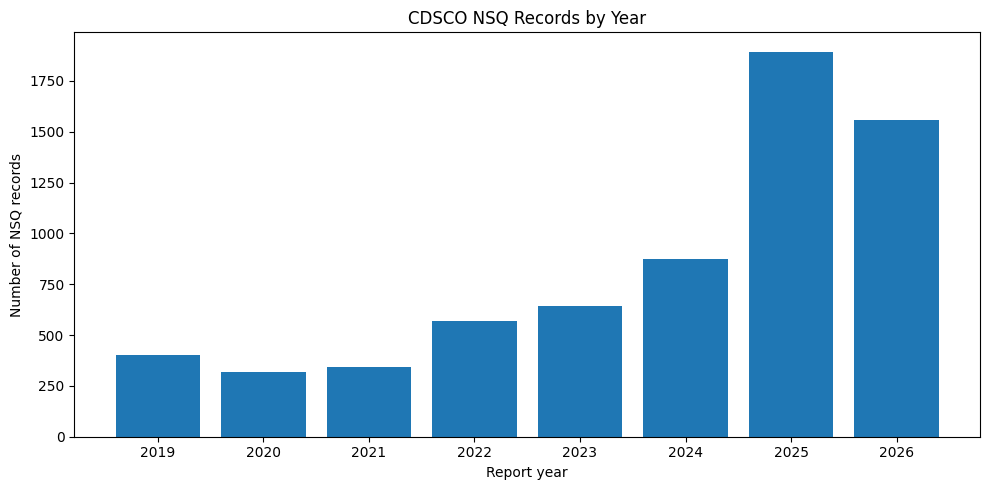

In [29]:
yearly = (
    df.dropna(subset=["report_year"])
      .assign(report_year=lambda x: x["report_year"].astype(int))
      .query("report_year >= 2019 and report_year <= 2026")
      .groupby("report_year").size()
      .rename("nsq_record_count").reset_index()
      .sort_values("report_year")
)
yearly["year_over_year_change"] = yearly["nsq_record_count"].diff()
yearly["year_over_year_percent"] = (yearly["nsq_record_count"].pct_change() * 100).round(2)
display(yearly)

plt.figure(figsize=(10, 5))
plt.bar(yearly["report_year"].astype(str), yearly["nsq_record_count"])
plt.title("CDSCO NSQ Records by Year")
plt.xlabel("Report year")
plt.ylabel("Number of NSQ records")
plt.tight_layout()
plt.show()

## 11. Monthly trend

,report_date,nsq_record_count
0,2019-01-01,45
1,2019-02-01,37
2,2019-03-01,51
3,2019-04-01,30
4,2019-05-01,32
5,2019-06-01,25
6,2019-07-01,18
7,2019-08-01,28
8,2019-09-01,21
9,2019-10-01,35


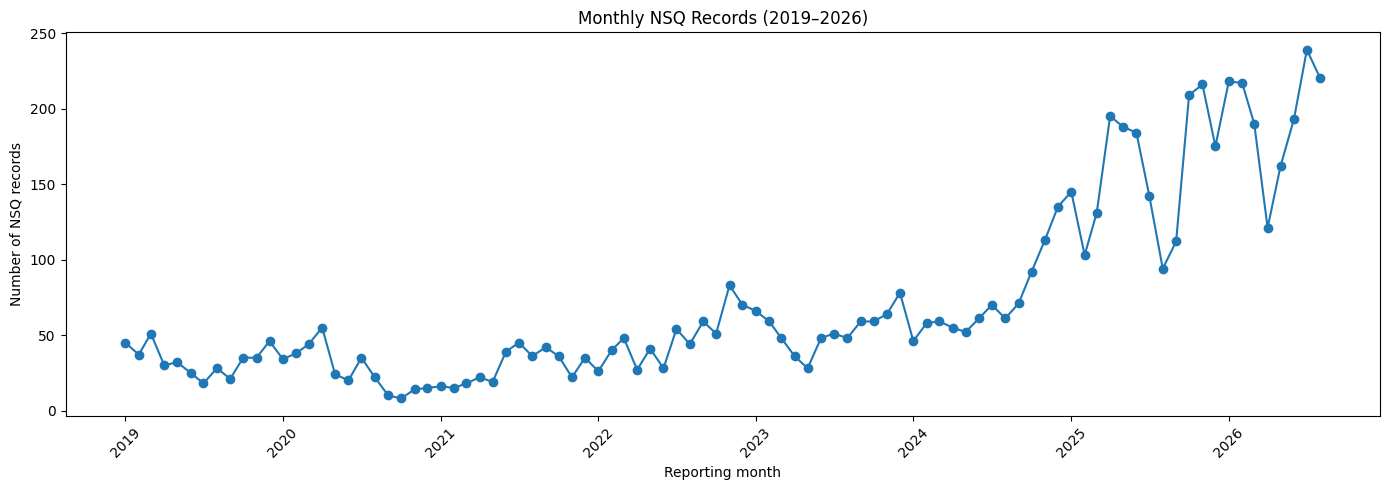

In [30]:
month_df = df.dropna(subset=["report_year", "report_month"]).copy()
month_df = month_df[
    month_df["report_year"].between(2019, 2026)
    & month_df["report_month"].between(1, 12)
]
month_df["report_date"] = pd.to_datetime({
    "year": month_df["report_year"].astype(int),
    "month": month_df["report_month"].astype(int),
    "day": 1
}, errors="coerce")

monthly = (
    month_df.dropna(subset=["report_date"])
    .groupby("report_date").size()
    .rename("nsq_record_count").reset_index()
    .sort_values("report_date")
)
display(monthly.head(12))

plt.figure(figsize=(14, 5))
plt.plot(monthly["report_date"], monthly["nsq_record_count"], marker="o")
plt.title("Monthly NSQ Records (2019–2026)")
plt.xlabel("Reporting month")
plt.ylabel("Number of NSQ records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 12. Quality category analysis

,quality_category,record_count,percent_of_records
0,Chemical/Content,4315,65.29
1,Physical,1375,20.8
2,Other/Identity,506,7.66
3,Microbiological,413,6.25


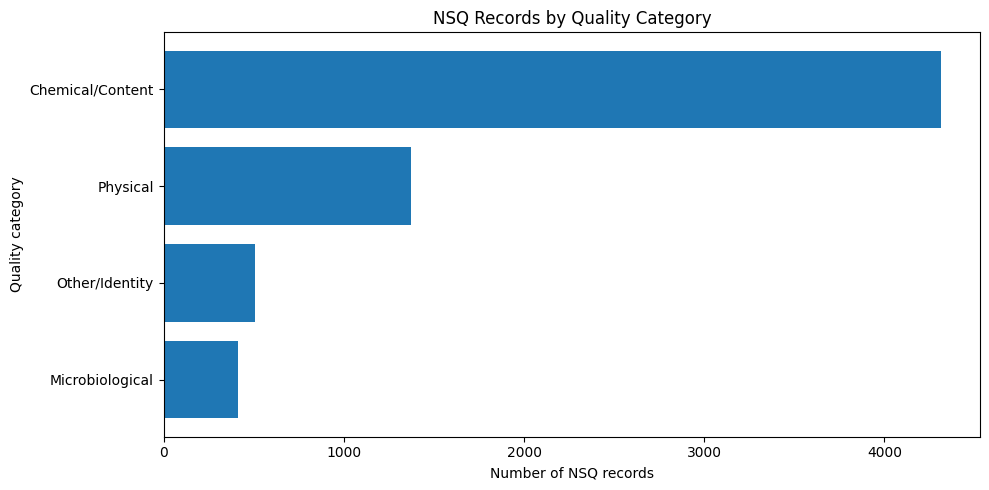

In [31]:
category_summary = (
    df["quality_category"].fillna("Unknown")
    .value_counts()
    .rename_axis("quality_category")
    .reset_index(name="record_count")
)
category_summary["percent_of_records"] = (
    category_summary["record_count"] / category_summary["record_count"].sum() * 100
).round(2)
display(category_summary)

plot_data = category_summary.sort_values("record_count")
plt.figure(figsize=(10, 5))
plt.barh(plot_data["quality_category"], plot_data["record_count"])
plt.title("NSQ Records by Quality Category")
plt.xlabel("Number of NSQ records")
plt.ylabel("Quality category")
plt.tight_layout()
plt.show()

## 13. Reporting source and laboratory analysis

,reporting_source,record_count,percent_of_records
0,State Lab,3510,53.11
1,CDSCO Lab,3098,46.88
2,Not Applicable,1,0.02


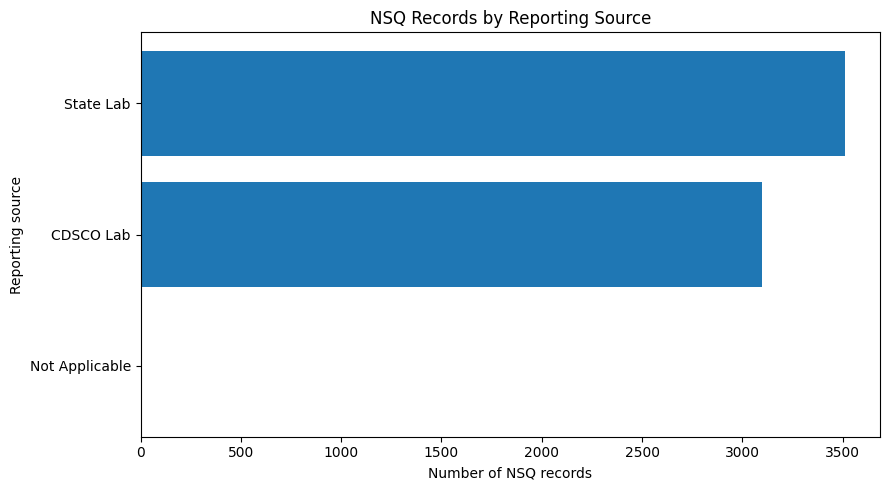

,reported_by_lab_or_state,record_count
0,CDL Kolkata,1248
1,RDTL Guwahati,774
2,RDTL Chandigarh,614
3,"CDL, Kolkata",402
4,CDTL Mumbai,275
5,DTL Thiruvananthapuram,159
6,"DTL, Bengaluru, Karnataka",123
7,"RDTL, Chandigarh",115
8,"RDTL, Guwahati",96
9,DTL Chennai,95


In [32]:
source_summary = (
    df["reporting_source"].fillna("Unknown")
    .value_counts()
    .rename_axis("reporting_source")
    .reset_index(name="record_count")
)
source_summary["percent_of_records"] = (
    source_summary["record_count"] / source_summary["record_count"].sum() * 100
).round(2)
display(source_summary)

plot_data = source_summary.sort_values("record_count")
plt.figure(figsize=(9, 5))
plt.barh(plot_data["reporting_source"], plot_data["record_count"])
plt.title("NSQ Records by Reporting Source")
plt.xlabel("Number of NSQ records")
plt.ylabel("Reporting source")
plt.tight_layout()
plt.show()

lab_summary = (
    df["reported_by_lab_or_state"].fillna("Unknown")
    .value_counts().head(15)
    .rename_axis("reported_by_lab_or_state")
    .reset_index(name="record_count")
)
display(lab_summary)

## 14. Product analysis

,product_name,nsq_record_count
0,Telmisartan Tablets IP 40 mg,43
1,Telmisartan Tablets IP 40mg,28
2,Paracetamol Tablets IP 500 mg,24
3,Albendazole Tablets IP 400 mg,23
4,Calcium and Vitamin D3 Tablets IP,22
5,Oxfendazole & Ivermectin Bolus (Vet.) WELLMOX-1,18
6,Aceclofenac & Paracetamol Tablets,17
7,Compound Sodium Lactate Injection I.P (Ringer’s Lactate I.P),16
8,Calcium Phosphate & Vitamin D3 Suspension,16
9,Paracetamol Tablets IP 650 mg,15


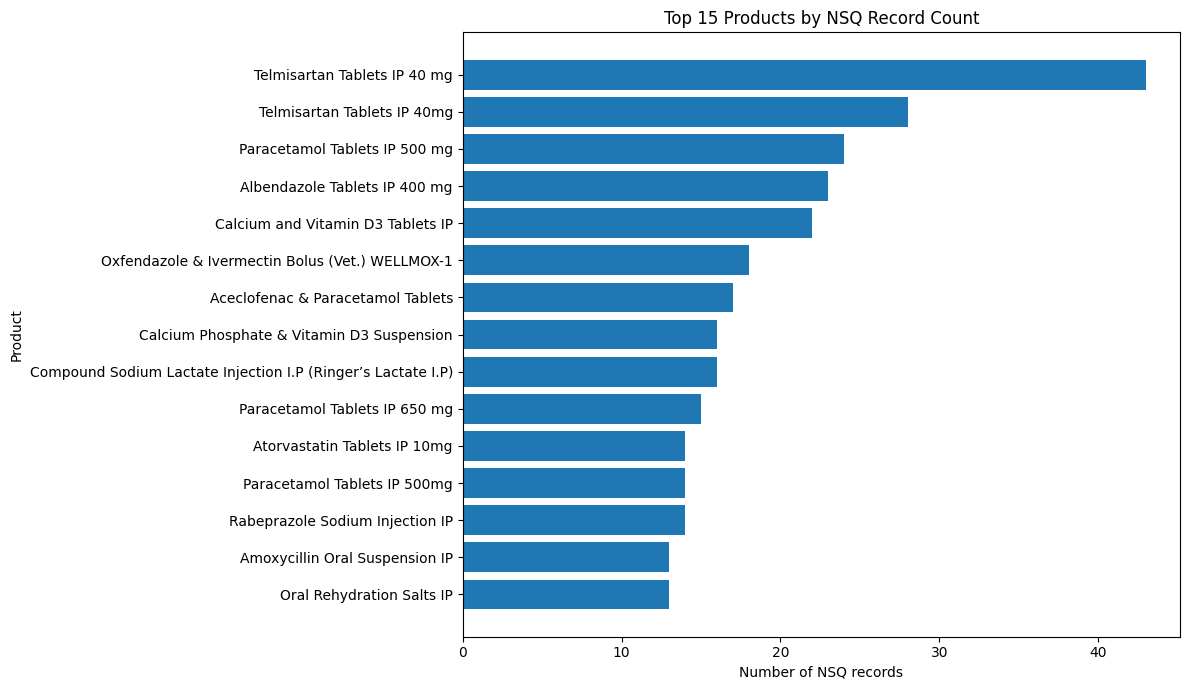

In [33]:
top_products = (
    df["product_name"].dropna().value_counts().head(15)
    .rename_axis("product_name").reset_index(name="nsq_record_count")
)
display(top_products)

plot_data = top_products.sort_values("nsq_record_count")
plt.figure(figsize=(12, 7))
plt.barh(plot_data["product_name"], plot_data["nsq_record_count"])
plt.title("Top 15 Products by NSQ Record Count")
plt.xlabel("Number of NSQ records")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

## 15. Manufacturer analysis

,manufacturer,nsq_record_count
0,"M/s.Argon Remedies Pvt. Ltd., Sarverkhera. Moradabad Road, Kashipur, U S Nagar, Uttarakhand-244713",18
1,"M/s. Paschim Banga Pharmaceuticals, (A Unit of Farista Vanijya Pvt. Ltd), NH- 31, TIN MILE HAT, ...",15
2,"Gidsha Pharmaceuticals Plot No. 611 612, Mega GIDC, Kharedi, Dahod 389151, Gujarat",15
3,"Yacca Lifesciences Pvt. Ltd. 156, Raipur, Bhagwanpur, Roorkee- 247661 (U.K.)",13
4,Under Investigation,12
5,"Aan Life science Private Limited., Survey No. 144/1, P1, Village. Ghodasar -387110. Ta. Mahemdab...",11
6,Not Mentioned,11
7,"M/s. Gidsha Pharmaceuticals, Plot No. 611 612, Mega GIDC, Kharedi, Dahod 389151, Gujarat.",10
8,Not Applicable,9
9,"Kerala Medical Services Corporation Ltd, Thycaud P.O, Thiruvananthapuram-14",9


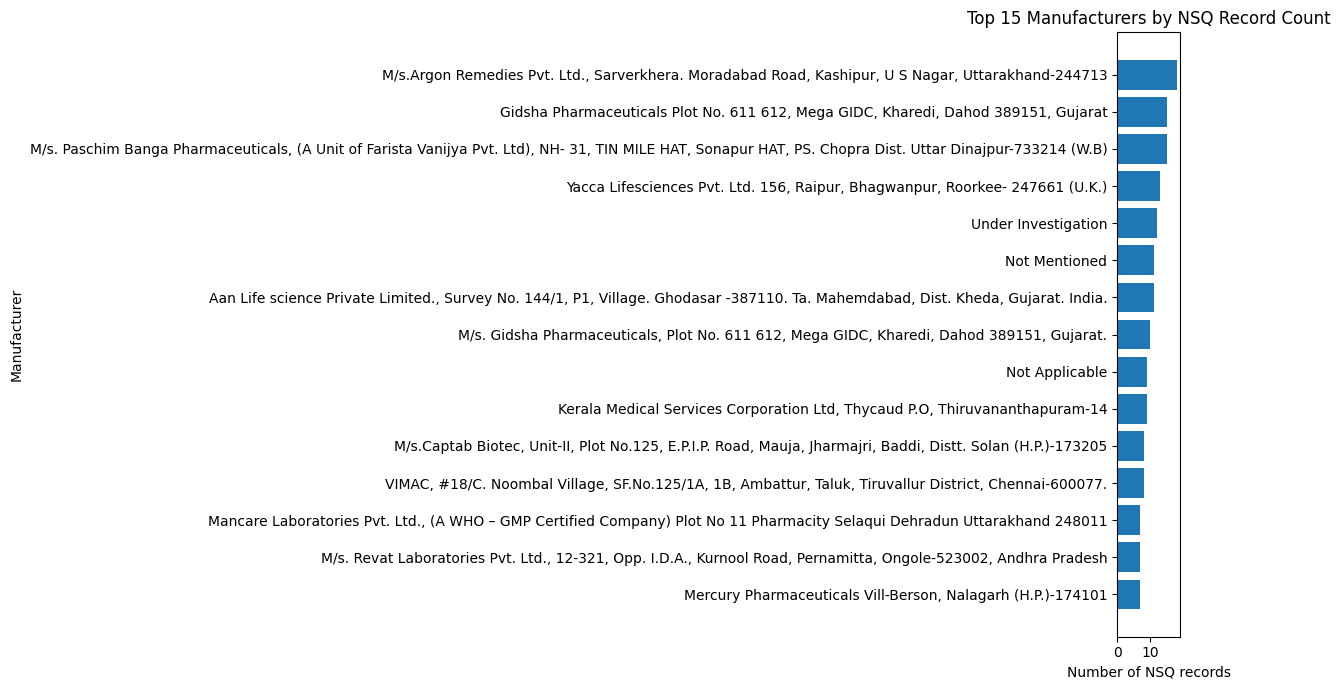

In [34]:
top_manufacturers = (
    df["manufactured_by"].dropna().value_counts().head(15)
    .rename_axis("manufacturer").reset_index(name="nsq_record_count")
)
display(top_manufacturers)

plot_data = top_manufacturers.sort_values("nsq_record_count")
plt.figure(figsize=(12, 7))
plt.barh(plot_data["manufacturer"], plot_data["nsq_record_count"])
plt.title("Top 15 Manufacturers by NSQ Record Count")
plt.xlabel("Number of NSQ records")
plt.ylabel("Manufacturer")
plt.tight_layout()
plt.show()

## 16. Manufacturer state and city analysis

,manufacturer_state,nsq_record_count
0,Himachal Pradesh,2049
1,Uttarakhand,1102
2,Gujarat,618
3,Madhya Pradesh,355
4,Maharashtra,284
5,Punjab,272
6,Uttar Pradesh,238
7,Haryana,226
8,Tamil Nadu,182
9,Telangana,179


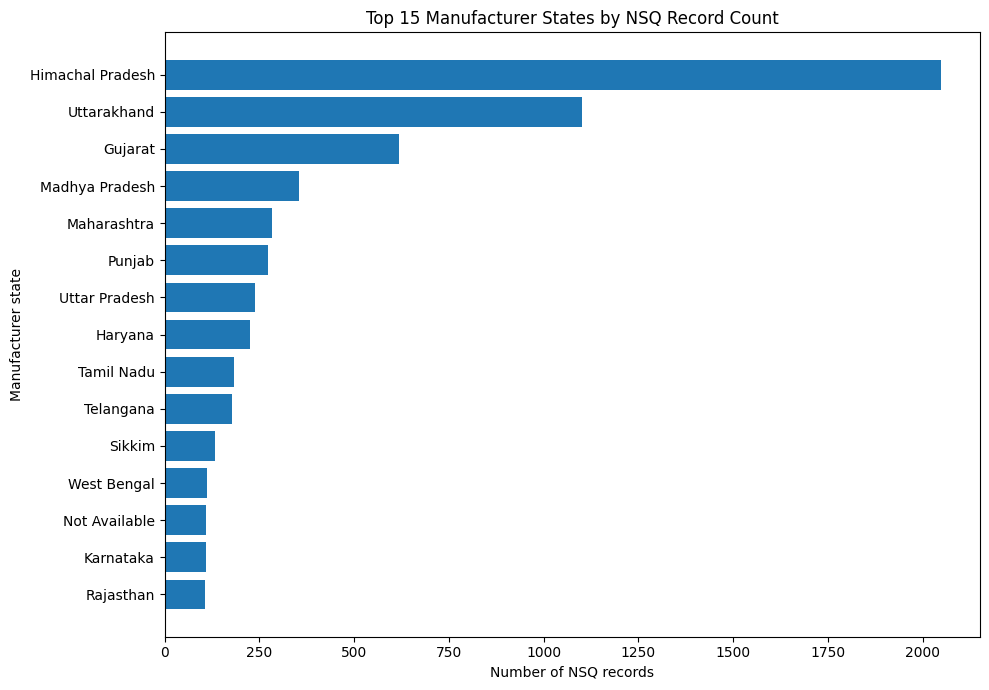

,manufacturer_city,nsq_record_count
0,Solan,1208
1,Haridwar,579
2,Not Available,233
3,Ahmedabad,228
4,Dehradun,220
5,Roorkee,208
6,Indore,185
7,Baddi,153
8,Paonta Sahib,146
9,Sirmour,145


In [35]:
top_states = (
    df["manufacturer_state"].dropna().value_counts().head(15)
    .rename_axis("manufacturer_state").reset_index(name="nsq_record_count")
)
display(top_states)

plot_data = top_states.sort_values("nsq_record_count")
plt.figure(figsize=(10, 7))
plt.barh(plot_data["manufacturer_state"], plot_data["nsq_record_count"])
plt.title("Top 15 Manufacturer States by NSQ Record Count")
plt.xlabel("Number of NSQ records")
plt.ylabel("Manufacturer state")
plt.tight_layout()
plt.show()

top_cities = (
    df["manufacturer_city"].dropna().value_counts().head(15)
    .rename_axis("manufacturer_city").reset_index(name="nsq_record_count")
)
display(top_cities)

## 17. Year vs quality category heatmap

quality_category,Chemical/Content,Microbiological,Other/Identity,Physical
report_year,,,,
2019,289,11,23,80
2020,227,14,23,55
2021,224,27,28,66
2022,411,57,19,84
2023,459,23,28,134
2024,569,43,69,192
2025,1153,150,160,431
2026,983,88,156,333


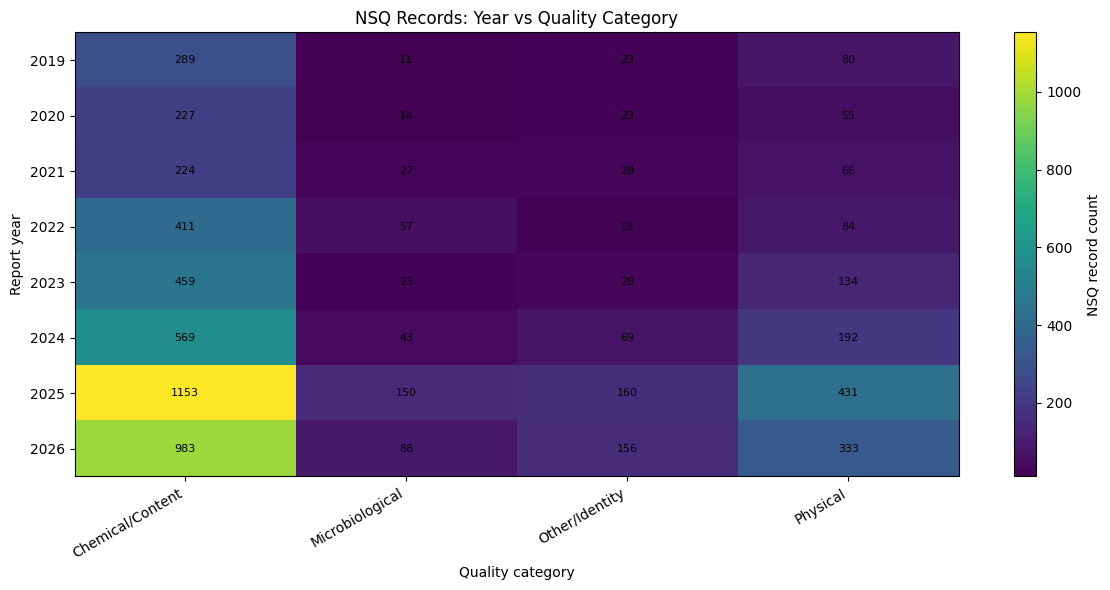

In [36]:
heatmap_df = df.dropna(subset=["report_year", "quality_category"]).copy()
heatmap_df = heatmap_df[heatmap_df["report_year"].between(2019, 2026)]
heatmap_df["report_year"] = heatmap_df["report_year"].astype(int)
year_category = pd.crosstab(heatmap_df["report_year"], heatmap_df["quality_category"]).sort_index()
display(year_category)

matrix = year_category.to_numpy()
plt.figure(figsize=(12, 6))
plt.imshow(matrix, aspect="auto")
plt.colorbar(label="NSQ record count")
plt.xticks(range(len(year_category.columns)), year_category.columns, rotation=30, ha="right")
plt.yticks(range(len(year_category.index)), year_category.index)
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        plt.text(j, i, str(matrix[i, j]), ha="center", va="center", fontsize=8)
plt.title("NSQ Records: Year vs Quality Category")
plt.xlabel("Quality category")
plt.ylabel("Report year")
plt.tight_layout()
plt.show()

## 18. Compare quality categories by reporting source

quality_category,Chemical/Content,Microbiological,Other/Identity,Physical
reporting_source,,,,
CDSCO Lab,2032,255,148,663
Not Applicable,1,0,0,0
State Lab,2282,158,358,712


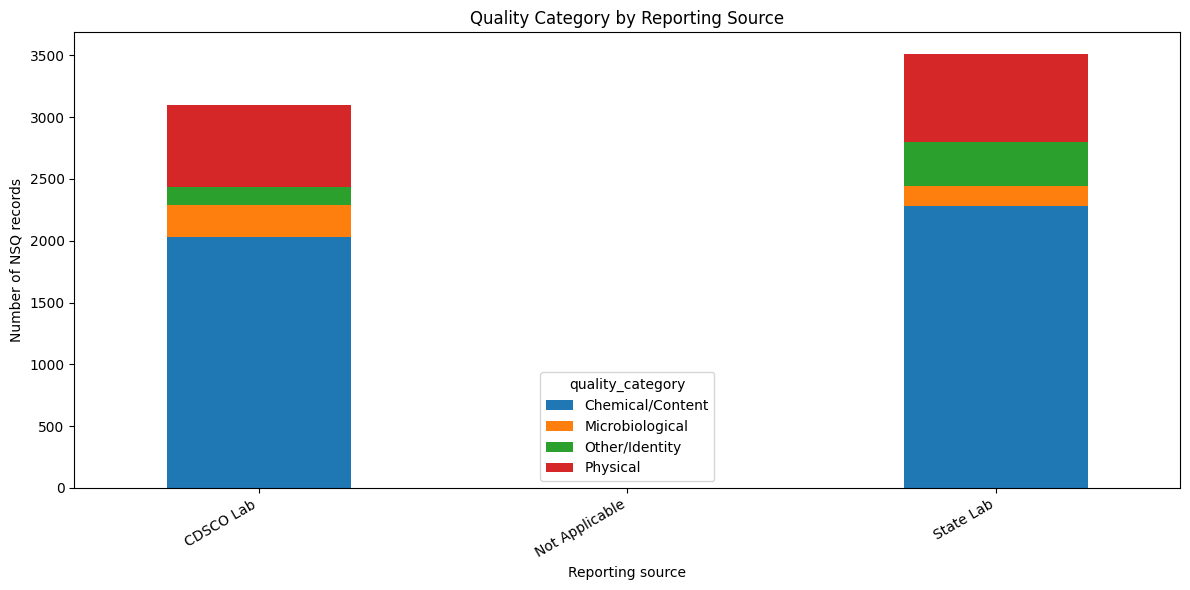

In [37]:
source_category = pd.crosstab(
    df["reporting_source"].fillna("Unknown"),
    df["quality_category"].fillna("Unknown")
)
display(source_category)

source_category.plot(kind="bar", stacked=True, figsize=(12, 6))
plt.title("Quality Category by Reporting Source")
plt.xlabel("Reporting source")
plt.ylabel("Number of NSQ records")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 19. Category indicator analysis

,category_flag,flag_count
0,category_chemical_content,4315
1,category_physical,1375
2,category_microbiological,413
3,category_other_identity,506


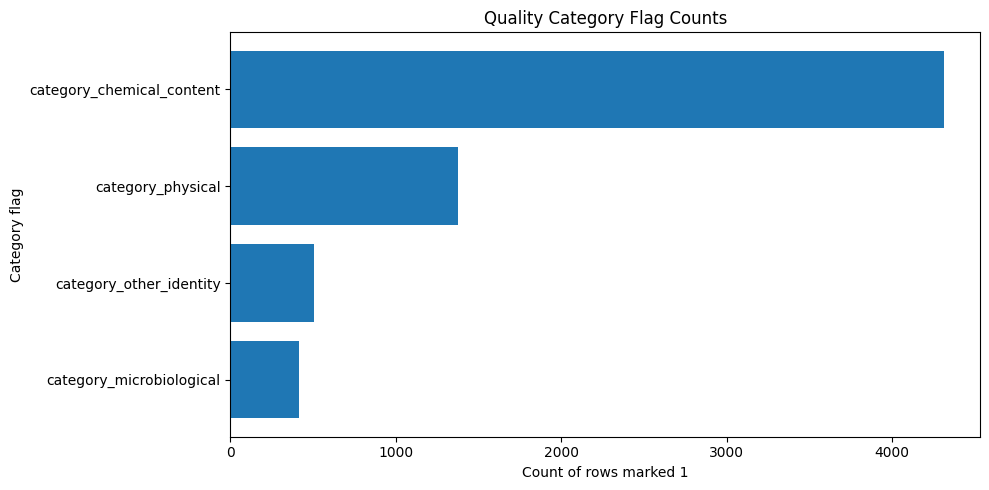

In [38]:
flag_summary = (
    df[flag_cols].apply(pd.to_numeric, errors="coerce").sum()
    .rename("flag_count").reset_index()
    .rename(columns={"index": "category_flag"})
)
display(flag_summary)

plot_data = flag_summary.sort_values("flag_count")
plt.figure(figsize=(10, 5))
plt.barh(plot_data["category_flag"], plot_data["flag_count"])
plt.title("Quality Category Flag Counts")
plt.xlabel("Count of rows marked 1")
plt.ylabel("Category flag")
plt.tight_layout()
plt.show()

## 20. Manufacturing-to-expiry date review

,product_name,batch_no,manufactured_by,manufacturing_date_parsed,expiry_date_parsed,days_between_manufacture_and_expiry
0,Amoxycillin & Potassium Clavulanete Tablets I.P. (Amofive CL 625),SBPT-4686,"M/s. Saitech Medicare Pvt. Ltd., Trilokpur Road, Kala-Amb, H.P.-173030",2018-05-01,2019-10-01,518.0
1,Amoxycillin And Potassium Clavulanate Tablets I.P.,SB58049,"M/s. Scott-Edil Pharmacia Ltd., 56, EPIP, Phase-I, Jharmajri-173205",2018-03-01,2020-02-01,702.0
2,C-Furo 750 mg (Cefuroxime Injection IP),B298005B,"M/s. ANG Life Sciences India Ltd., Village-Kishanpura, Nalagarh Road, Tehsil Baddi, Distt. Solan...",2018-08-01,2020-07-01,700.0
3,"COR-3 (L- Methylfolate, Methylcobalamin & Pyridoxal-5- phosphate Tablets)",CG18034,"M/s. Corona Remedies Pvt. Ltd., Village Jatolli, P.O. Oachghat, Tahsil-Solan, Dist. Solan (HP)-1...",2018-04-01,2019-09-01,518.0
4,Calcium and Vitamin D3 Tablets (ORTHOCAL-500 TABLETS),TP-3286,"B. No.: TP-3286, Mfg dt: 03/2018, Exp dt: 02/2020, Mfd by: M/s. Ticoma Pharmacia, E-17, Focal Po...",2018-03-01,2020-02-01,702.0
5,Calcium and Vitamin D3 Tablets IP (CALCICAL TABLETS),8S17004,"B. No.: PT-180905, Mfg dt: 09/2018, Exp dt: 08/2019, Mfd by: M/s. Panther Health Care Pvt. Ltd.,...",2018-09-01,2019-08-01,334.0
6,Cefixime Tablets I.P.,MCT-16123,"M/s. Maxmed Lifesciences Pvt. Ltd., Plot No. 54, Sector IIDC, SIDCUL, Rudrapur, Uttarakhand",2017-03-01,2019-02-01,702.0
7,Cefpodoxime Proxetil Tablets I.P.200 mg. (Pizicef- 200),SBT-367,"M/s. Sarthak Biotech Pvt. Ltd., 198-A, Sector-3, HSHDC, Karnal, Haryana-132001",2018-07-01,2020-06-01,701.0
8,Cyproheptadine and Tricholine Oral Drops (CYP-L DROPS),8S17004,"B. No.: 8S17004, Mfg dt: 05/2018, Exp dt: 04/2020, Mfd by: M/s. Albert David Ltd., 5/11, D.Gupta...",2018-05-01,2020-04-01,701.0
9,Diclofenac Gel B.P.,D8173,"M/s. Vivek Pharmachem (India) Ltd., EPIP, Kartholi, Bari-Brahmana, Jammu 181133 (J&K)",2018-07-01,2020-07-01,731.0


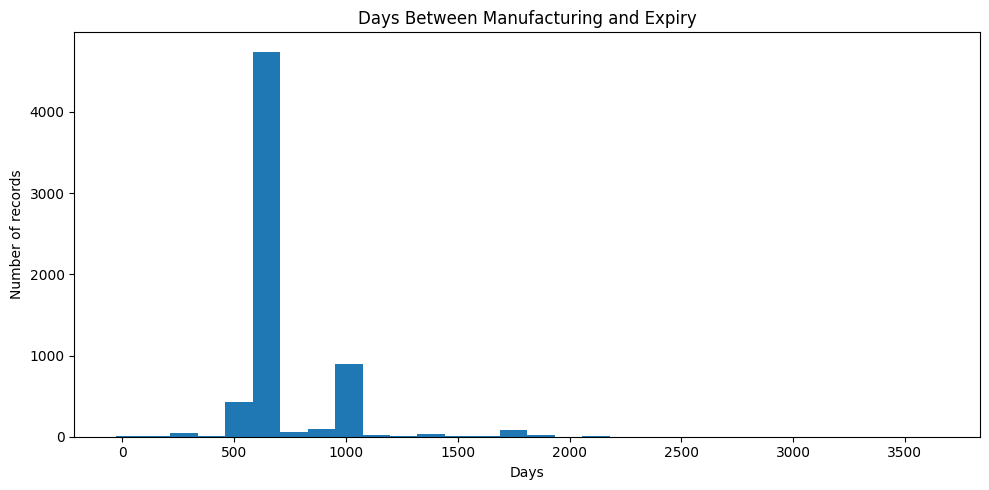

In [39]:
date_review = df[[
    "product_name", "batch_no", "manufactured_by",
    "manufacturing_date_parsed", "expiry_date_parsed"
]].copy()
date_review["days_between_manufacture_and_expiry"] = (
    date_review["expiry_date_parsed"] - date_review["manufacturing_date_parsed"]
).dt.days

display(date_review.head(10))

valid_days = date_review["days_between_manufacture_and_expiry"].dropna()
if not valid_days.empty:
    plt.figure(figsize=(10, 5))
    plt.hist(valid_days, bins=30)
    plt.title("Days Between Manufacturing and Expiry")
    plt.xlabel("Days")
    plt.ylabel("Number of records")
    plt.tight_layout()
    plt.show()
else:
    print("No usable date pairs were found for this chart.")

## 21. Generate insights from the actual dataset

In [40]:
insights = []

if not yearly.empty:
    peak = yearly.loc[yearly["nsq_record_count"].idxmax()]
    insights.append(
        f"- **Year with the most records:** {int(peak['report_year'])} "
        f"({int(peak['nsq_record_count']):,} records)."
    )
    if len(yearly) >= 2:
        latest = yearly.iloc[-1]
        if pd.notna(latest["year_over_year_percent"]):
            insights.append(
                f"- **Latest year shown:** {int(latest['report_year'])} has "
                f"{int(latest['nsq_record_count']):,} records; change from the prior year "
                f"is {latest['year_over_year_percent']:.2f}%. Verify whether the year is complete."
            )

if not category_summary.empty:
    top = category_summary.iloc[0]
    insights.append(
        f"- **Most common quality category:** {top['quality_category']} — "
        f"{int(top['record_count']):,} records ({top['percent_of_records']:.2f}%)."
    )

if not source_summary.empty:
    top = source_summary.iloc[0]
    insights.append(
        f"- **Most common reporting source:** {top['reporting_source']} — "
        f"{int(top['record_count']):,} records ({top['percent_of_records']:.2f}%)."
    )

if not top_products.empty:
    top = top_products.iloc[0]
    insights.append(
        f"- **Product with the highest recorded count:** {top['product_name']} "
        f"({int(top['nsq_record_count']):,} records)."
    )

if not top_manufacturers.empty:
    top = top_manufacturers.iloc[0]
    insights.append(
        f"- **Manufacturer with the highest recorded count:** {top['manufacturer']} "
        f"({int(top['nsq_record_count']):,} records)."
    )

if not top_states.empty:
    top = top_states.iloc[0]
    insights.append(
        f"- **State with the highest manufacturer-linked count:** {top['manufacturer_state']} "
        f"({int(top['nsq_record_count']):,} records)."
    )

insights.append(
    "- **Important limitation:** these are counts of reported NSQ records, not failure rates. "
    "The dataset does not include the total number of batches tested."
)
insights.append(
    "- **Data completeness caution:** the most recent year may be incomplete. "
    "Review missing values, repeated product/batch pairs, and inconsistent names before drawing conclusions."
)

display(Markdown("# Initial insights\n\n" + "\n".join(insights)))

# Initial insights

- **Year with the most records:** 2025 (1,894 records).
- **Latest year shown:** 2026 has 1,560 records; change from the prior year is -17.63%. Verify whether the year is complete.
- **Most common quality category:** Chemical/Content — 4,315 records (65.29%).
- **Most common reporting source:** State Lab — 3,510 records (53.11%).
- **Product with the highest recorded count:** Telmisartan Tablets IP 40 mg (43 records).
- **Manufacturer with the highest recorded count:** M/s.Argon Remedies Pvt. Ltd., Sarverkhera. Moradabad Road, Kashipur, U S Nagar, Uttarakhand-244713 (18 records).
- **State with the highest manufacturer-linked count:** Himachal Pradesh (2,049 records).
- **Important limitation:** these are counts of reported NSQ records, not failure rates. The dataset does not include the total number of batches tested.
- **Data completeness caution:** the most recent year may be incomplete. Review missing values, repeated product/batch pairs, and inconsistent names before drawing conclusions.